# Eksperimen Image Enhancement dengan `PIL.ImageEnhance`

Tugas:
1. Mencoba program Image Enhancement dari perkuliahan (`asetya/BigData/Image_enhanced_ipnyb.ipynb`).
2. Mengamati koefisien (*factor*) yang dapat di-set pada tiap operasi — **Brightness, Contrast, Sharpness, Color** — dan melaporkan pengaruhnya.
3. Menggunakan gambar berwarna lain dan mengamati perilaku algoritmanya.

**Gambar uji:** foto kucing *Chelsea* (RGB, 451×300 px) dari `skimage.data`, dipilih karena berwarna, punya bulu bertekstur halus (bagus untuk menguji *sharpness*), area terang–gelap (bagus untuk *brightness/contrast*), dan warna oranye-cokelat yang jelas (bagus untuk *color*).
Notebook ini bisa langsung dijalankan di Colab tanpa Google Drive. Untuk memakai gambar sendiri, isi variabel `PATH_GAMBAR`.

Ukuran: (600, 400) | Mode: RGB


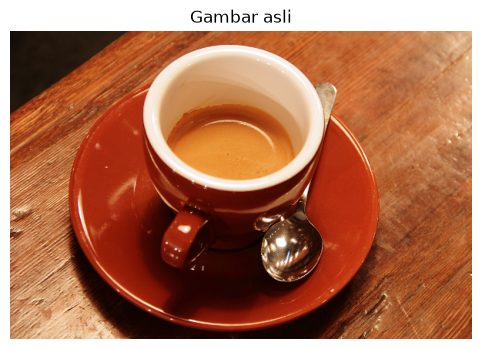

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageEnhance
from skimage import data

PATH_GAMBAR = None   # contoh: '/content/drive/MyDrive/Image_proc/gambar_saya.jpg'

if PATH_GAMBAR:
    image = Image.open(PATH_GAMBAR).convert('RGB')
else:
    image = Image.fromarray(data.coffee()).convert('RGB')

print('Ukuran:', image.size, '| Mode:', image.mode)
plt.figure(figsize=(6, 4)); plt.imshow(image); plt.title('Gambar asli'); plt.axis('off'); plt.show()

## 1. Cara kerja `ImageEnhance` (dasar untuk membaca koefisien)

Keempat kelas di `ImageEnhance` memakai **rumus yang sama**, yaitu interpolasi/ekstrapolasi linier antara gambar asli dan sebuah **gambar "degenerate"**:

$$\text{output} = \text{degenerate} \cdot (1 - f) + \text{asli} \cdot f$$

lalu hasilnya di-*clip* ke rentang 0–255. Yang membedakan tiap operasi hanyalah gambar degenerate-nya:

| Operasi | Gambar degenerate | Arti `factor = 0` |
|---|---|---|
| `Brightness` | gambar hitam (semua piksel 0) | gambar hitam total |
| `Contrast` | gambar abu-abu rata (nilai = rata-rata luminans gambar) | abu-abu polos |
| `Color` | versi grayscale dari gambar | gambar hitam-putih |
| `Sharpness` | versi gambar yang diblur (filter `SMOOTH` 3×3) | gambar sedikit blur |

Konsekuensinya berlaku untuk semua operasi:
- **`f = 1`** → gambar asli, tidak berubah.
- **`0 < f < 1`** → interpolasi: gambar bergerak *menuju* versi degenerate (lebih gelap / datar / pucat / blur).
- **`f > 1`** → ekstrapolasi: gambar didorong *menjauhi* versi degenerate (lebih terang / kontras / jenuh / tajam). Karena hasil harus di-clip ke 0–255, nilai besar menyebabkan **saturasi/clipping** dan detail hilang.
- Nilai negatif secara teknis juga bisa (menghasilkan efek "inversi" terhadap degenerate), tapi jarang dipakai.

Verifikasi rumus pada satu piksel (Brightness, degenerate = 0, jadi output = asli × f):

In [21]:
px = np.asarray(image)[150, 200].astype(float)
for f in [0.5, 1.5, 3]:
    out = np.asarray(ImageEnhance.Brightness(image).enhance(f))[150, 200]
    manual = np.clip(px * f, 0, 255).astype(int)   # PIL membulatkan ke bawah
    print(f'f={f}: asli={px.astype(int)}, PIL={out}, rumus manual={manual}')

f=0.5: asli=[247 235 218], PIL=[123 117 109], rumus manual=[123 117 109]
f=1.5: asli=[247 235 218], PIL=[255 255 255], rumus manual=[255 255 255]
f=3: asli=[247 235 218], PIL=[255 255 255], rumus manual=[255 255 255]


## 2. Fungsi bantu: galeri, histogram, dan metrik kuantitatif

Agar pengaruh koefisien tidak hanya dinilai secara visual, tiap hasil diukur dengan metrik sederhana:
- **Mean L** — rata-rata luminans (0–255): ukuran kecerahan.
- **Std L** — simpangan baku luminans: ukuran kontras global.
- **Mean S** — rata-rata saturasi pada ruang HSV (0–255): ukuran kepekatan warna.
- **Var Laplacian** — varians hasil filter Laplacian: ukuran ketajaman/energi tepi.
- **% Clipped** — persentase piksel yang minimal satu kanalnya bernilai 0 atau 255: indikator detail yang hilang.

In [22]:
FACTORS = [0, 0.5, 1, 1.5, 2, 3, 5]
OPS = {
    'Brightness': ImageEnhance.Brightness,
    'Contrast':   ImageEnhance.Contrast,
    'Color':      ImageEnhance.Color,
    'Sharpness':  ImageEnhance.Sharpness,
}

def laplacian_var(gray):
    g = gray.astype(float)
    lap = (-4 * g[1:-1, 1:-1] + g[:-2, 1:-1] + g[2:, 1:-1] + g[1:-1, :-2] + g[1:-1, 2:])
    return lap.var()

def metrik(im):
    rgb = np.asarray(im)
    L = np.asarray(im.convert('L'))
    S = np.asarray(im.convert('HSV'))[..., 1]
    clipped = ((rgb == 0) | (rgb == 255)).any(axis=2).mean() * 100
    return {'Mean L': L.mean(), 'Std L': L.std(), 'Mean S': S.mean(),
            'Var Laplacian': laplacian_var(L), '% Clipped': clipped}

def eksperimen(nama, factors=FACTORS, crop=None):
    enh = OPS[nama](image)
    hasil = {f: enh.enhance(f) for f in factors}
    # galeri
    fig, ax = plt.subplots(1, len(factors), figsize=(3 * len(factors), 2.6))
    for a, (f, im) in zip(ax, hasil.items()):
        a.imshow(im.crop(crop) if crop else im); a.set_title(f'factor = {f}'); a.axis('off')
    fig.suptitle(f'ImageEnhance.{nama}' + (' (zoom)' if crop else ''), fontsize=14); plt.tight_layout(); plt.show()
    # tabel metrik
    df = pd.DataFrame({f: metrik(im) for f, im in hasil.items()}).T.round(1)
    df.index.name = 'factor'
    return hasil, df

def histogram(hasil, pilih, judul):
    fig, ax = plt.subplots(1, len(pilih), figsize=(4 * len(pilih), 2.6), sharey=True)
    for a, f in zip(ax, pilih):
        arr = np.asarray(hasil[f])
        for i, c in enumerate('rgb'):
            a.hist(arr[..., i].ravel(), bins=64, range=(0, 255), color=c, alpha=.45)
        a.set_title(f'factor = {f}'); a.set_xlim(0, 255)
    fig.suptitle(judul); plt.tight_layout(); plt.show()

## 3. Brightness

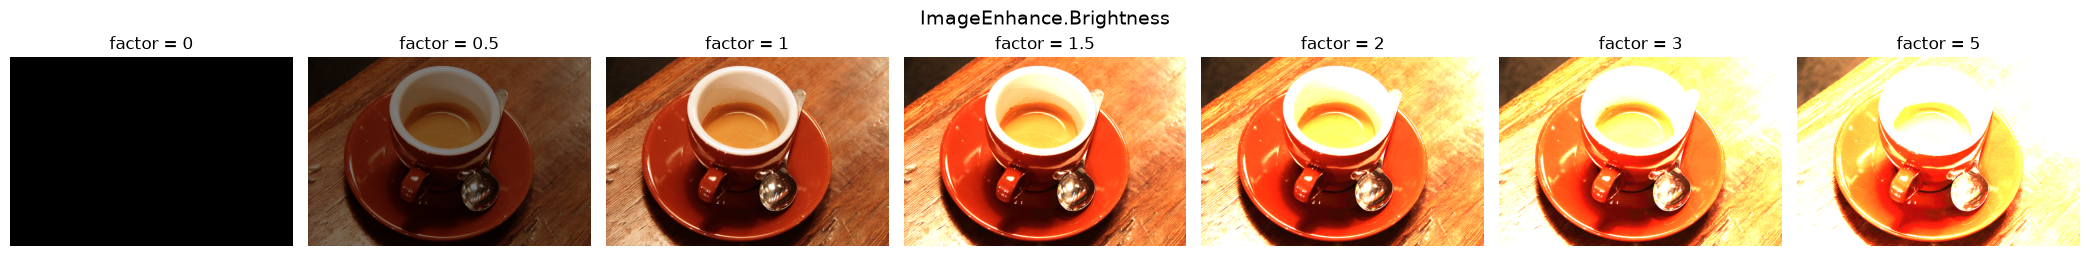

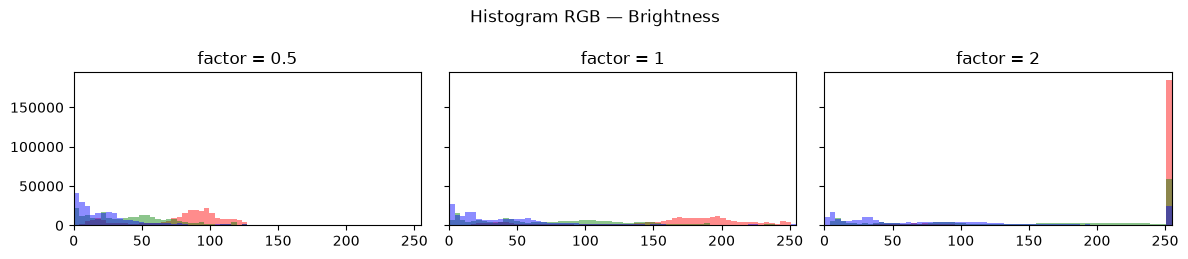

,Mean L,Std L,Mean S,Var Laplacian,% Clipped
factor,,,,,
0.0,0.0,0.0,0.0,0.0,100.0
0.5,51.6,29.1,185.4,385.0,4.4
1.0,103.6,58.1,184.4,1534.6,1.6
1.5,143.7,71.8,175.0,2146.8,57.1
2.0,165.7,75.4,157.5,2121.3,78.0
3.0,189.5,73.9,129.6,1752.4,83.7
5.0,211.3,64.6,94.7,1207.0,88.1


In [23]:
hasil_b, df_b = eksperimen('Brightness')
histogram(hasil_b, [0.5, 1, 2], 'Histogram RGB — Brightness')
df_b

**Pengamatan Brightness**
- Koefisien bekerja sebagai **pengali langsung** setiap kanal: `output = asli × f`. Terlihat dari Mean L yang naik hampir linier (≈60 → 120 → 177 untuk f = 0.5 → 1 → 1.5).
- **f = 0** → gambar hitam total; **f < 1** menggelapkan, histogram menyempit dan bergeser ke kiri. Detail masih terjaga (clipping ≈0%), hanya tampak redup.
- **f > 1** menerangkan, tetapi histogram terdorong ke kanan dan menumpuk di 255. Mulai **f = 1.5 sekitar seperempat piksel sudah ter-clip**, dan pada f = 2 lebih dari 3/4 piksel ter-clip (bulu putih kucing menjadi putih polos tanpa tekstur).
- Efek samping yang menarik: pada f besar **saturasi justru turun** (Mean S 110 → 41 pada f = 3). Penyebabnya, kanal yang lebih terang (R pada warna oranye) ter-clip di 255 lebih dulu sementara G dan B terus naik, sehingga ketiganya mendekat dan warna memudar ke putih. Std L juga turun lagi setelah f ≈ 1.5 karena semuanya menyatu di putih.
- **Rentang yang wajar:** sekitar 0.7–1.3 untuk koreksi pencahayaan tanpa kehilangan detail.

## 4. Contrast

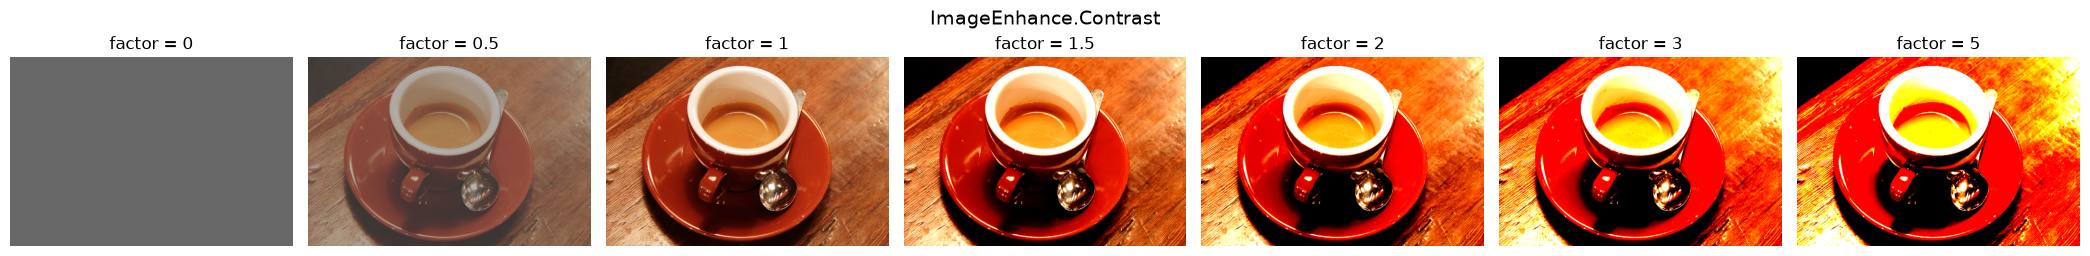

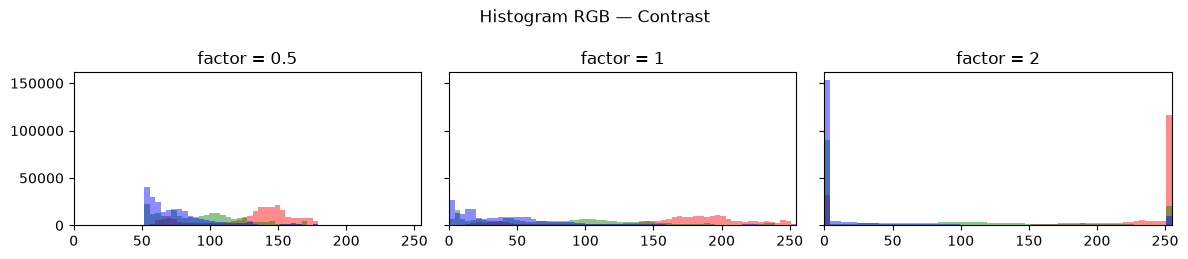

,Mean L,Std L,Mean S,Var Laplacian,% Clipped
factor,,,,,
0.0,104.0,0.0,0.0,0.0,0.0
0.5,103.6,29.1,101.5,385.0,0.0
1.0,103.6,58.1,184.4,1534.6,1.6
1.5,106.5,72.7,194.9,2765.0,69.1
2.0,109.9,77.5,185.8,3476.7,96.6
3.0,113.3,81.9,181.9,4385.2,99.9
5.0,115.6,85.9,177.2,5819.6,100.0


In [24]:
hasil_c, df_c = eksperimen('Contrast')
histogram(hasil_c, [0.5, 1, 2], 'Histogram RGB — Contrast')
df_c

**Pengamatan Contrast**
- Contrast meregangkan/menyempitkan nilai piksel **di sekitar rata-rata luminans gambar** (≈119 untuk gambar ini), bukan di sekitar 0. Karena itu Mean L hampir tidak berubah, sedangkan **Std L naik sebanding dengan f** (16 → 32 → 47 → 58 untuk f = 0.5 → 1 → 1.5 → 2).
- **f = 0** → seluruh gambar menjadi abu-abu polos (Std L = 0). **f < 1** → gambar kusam/berkabut, histogram mengerut ke tengah.
- **f > 1** → gelap makin gelap, terang makin terang; histogram melebar ke dua sisi. Pada f = 2 sekitar sepertiga piksel ter-clip, pada f = 4 (nilai di notebook dosen) hampir seluruh gambar ter-clip menjadi area warna-warna solid seperti efek poster.
- Contrast juga **menaikkan saturasi** (Mean S 110 → 171 pada f = 2) karena selisih antar-kanal R, G, B ikut diperbesar. Jadi Contrast tinggi membuat warna lebih "ngejreng" sekaligus.
- **Rentang yang wajar:** sekitar 1.1–1.5 untuk gambar yang kusam; di atas 2 artefak clipping sudah dominan.

## 5. Color (saturasi)

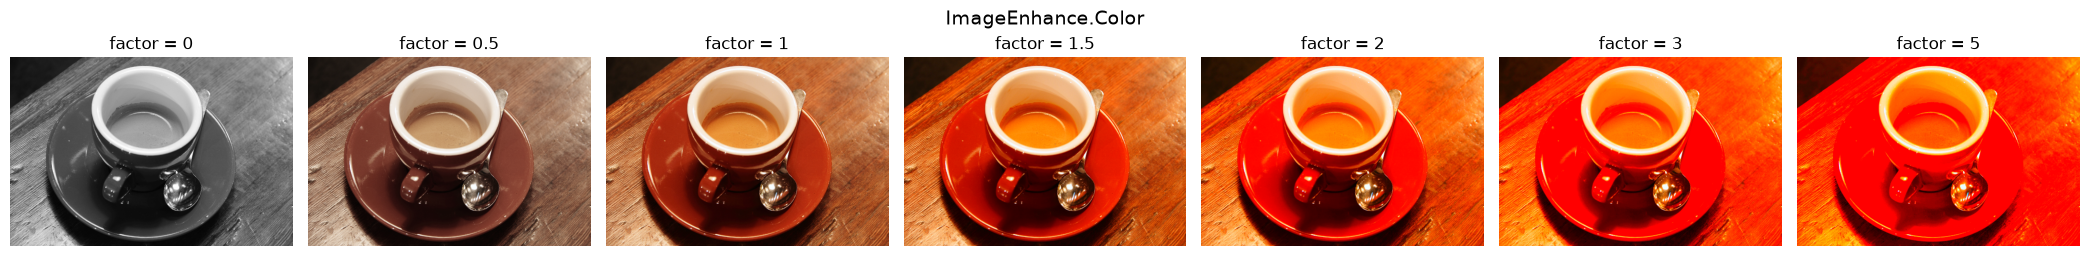

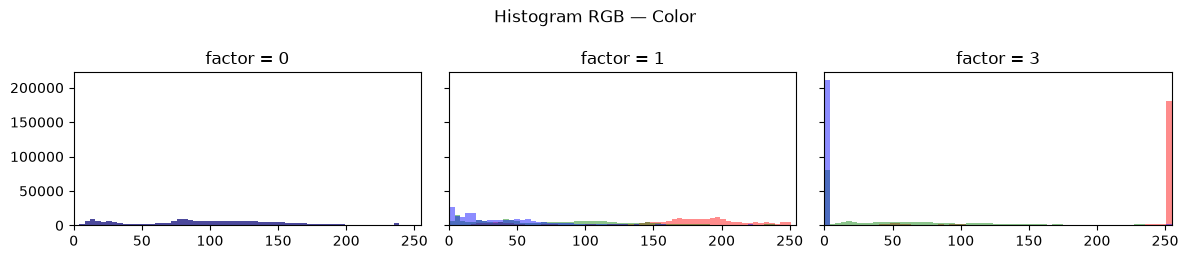

,Mean L,Std L,Mean S,Var Laplacian,% Clipped
factor,,,,,
0.0,103.6,58.1,0.0,1534.6,0.0
0.5,103.5,58.1,118.7,1534.5,0.0
1.0,103.6,58.1,184.4,1534.6,1.6
1.5,103.8,57.6,220.8,1472.3,47.6
2.0,104.7,55.9,235.1,1256.9,84.4
3.0,101.6,51.1,243.8,944.1,99.5
5.0,93.6,44.1,248.5,883.0,99.9


In [25]:
hasil_k, df_k = eksperimen('Color')
histogram(hasil_k, [0, 1, 3], 'Histogram RGB — Color')
df_k

**Pengamatan Color**
- Color mengatur **kepekatan warna (saturasi)** dengan menginterpolasi antara versi grayscale dan gambar asli. Yang berubah hampir hanya Mean S (0 → 62 → 110 → 148 → 176 untuk f = 0 → 2), sementara **kecerahan (Mean L) dan kontras (Std L) nyaris tetap**. Ini operasi yang paling "bersih" efeknya.
- **f = 0** → gambar hitam-putih sempurna (Mean S = 0); terlihat di histogram, tiga kanal RGB berimpit. **f < 1** → warna pucat/*desaturated*.
- **f > 1** → warna makin pekat. Sampai f ≈ 1.5 masih natural; mulai f = 2 warna oranye bulu tampak tidak wajar, dan pada f = 3–5 kanal mulai ter-clip (41% dan 83% piksel), menghasilkan blok warna jenuh dan *color banding*, serta tekstur halus berkurang (Var Laplacian turun 402 → 242).
- Gambar yang warnanya dominan satu rona (oranye–cokelat) seperti ini cepat terlihat berlebihan; pada gambar yang hampir abu-abu, efek Color akan jauh lebih kecil karena tidak ada warna untuk diperkuat.
- **Rentang yang wajar:** sekitar 0.8–1.5.

## 6. Sharpness

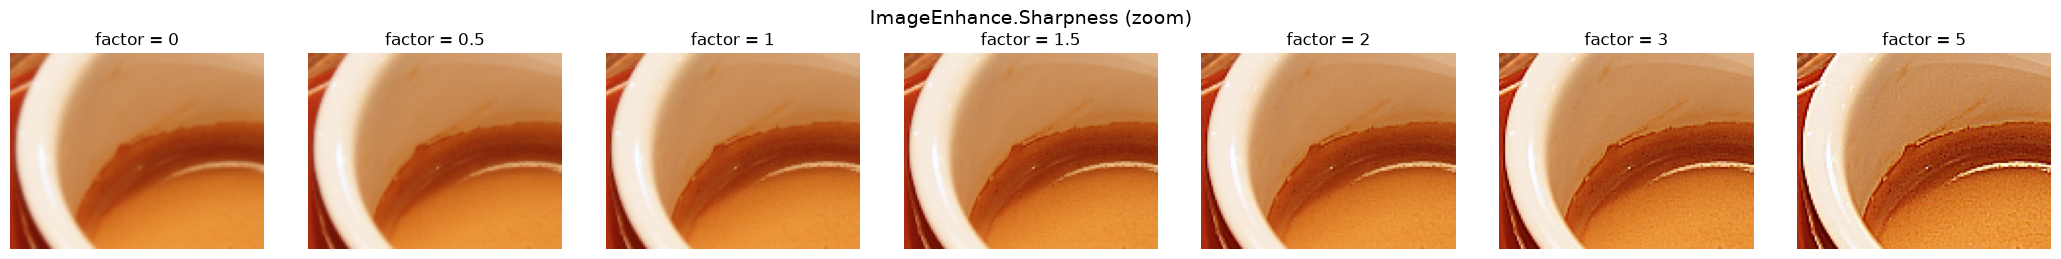

,Mean L,Std L,Mean S,Var Laplacian,% Clipped
factor,,,,,
0.0,103.6,57.0,183.7,243.5,0.2
0.5,103.4,57.5,184.4,729.1,0.9
1.0,103.6,58.1,184.4,1534.6,1.6
1.5,103.4,58.8,185.1,2616.3,3.9
2.0,103.6,59.6,185.0,3913.3,5.3
3.0,103.6,61.3,185.2,6969.2,8.9
5.0,103.4,64.4,184.6,13742.6,15.6


In [26]:
# zoom ke area mata & bulu agar efek ketajaman terlihat
hasil_s, df_s = eksperimen('Sharpness', crop=(170, 60, 300, 160))
df_s

**Pengamatan Sharpness**
- Sharpness bekerja dengan **mencampur gambar asli dengan versi blur-nya**. f > 1 berarti "mengurangkan blur" dari gambar asli — pada dasarnya teknik *unsharp masking*.
- **f = 0** → gambar menjadi blur (Var Laplacian turun 402 → 69); f = 0.5 sedikit lembut.
- **f > 1** → tepi dan tekstur bulu makin tegas; Var Laplacian naik konsisten (704 → 1091 → 2126 → 5112 untuk f = 1.5 → 2 → 3 → 5). Brightness dan warna hampir tidak berubah (Mean L dan Mean S stabil).
- Pada f besar (≥3) muncul **artefak**: *noise* dan butiran JPEG ikut diperkuat, muncul *halo* terang/gelap di sekitar tepi (misal pada kumis dan tepi mata), dan sedikit clipping (2.5% pada f = 5).
- Efek Sharpness **sangat bergantung ukuran tampilan**: pada gambar penuh perubahan f = 1 → 3 tampak halus, baru terlihat jelas saat di-*zoom*. Ini karena filter blur yang dipakai hanya 3×3 sehingga hanya memengaruhi detail skala piksel.
- **Rentang yang wajar:** sekitar 1.2–2.

## 7. Ringkasan perbandingan

Grafik berikut menunjukkan metrik yang paling dipengaruhi tiap operasi terhadap factor, sehingga terlihat jelas operasi mana mengubah apa.

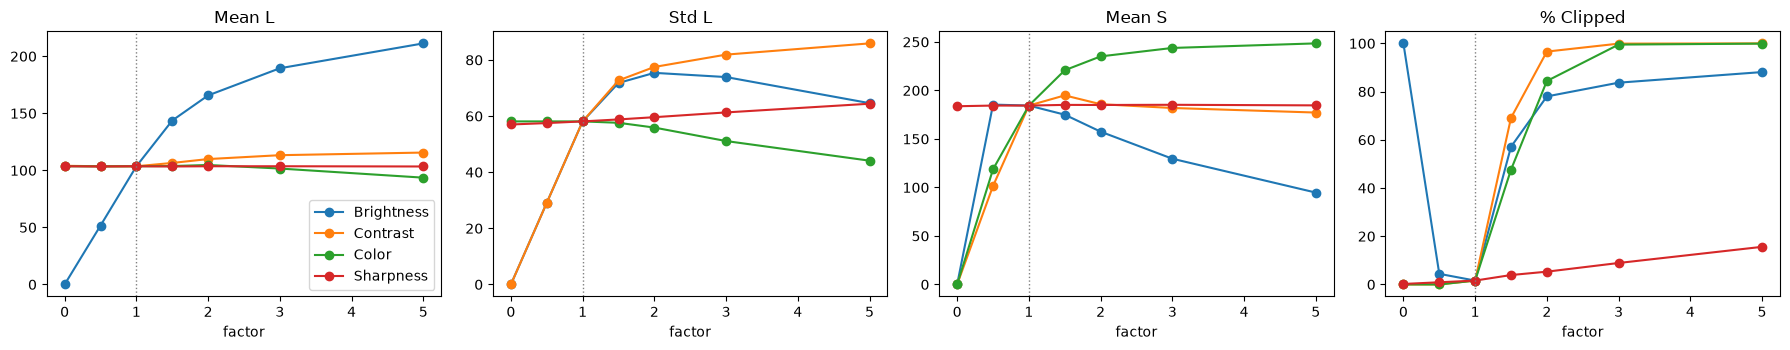

In [27]:
fig, ax = plt.subplots(1, 4, figsize=(18, 3.6))
dfs = {'Brightness': df_b, 'Contrast': df_c, 'Color': df_k, 'Sharpness': df_s}
for a, kol in zip(ax, ['Mean L', 'Std L', 'Mean S', '% Clipped']):
    for nama, df in dfs.items():
        a.plot(df.index, df[kol], marker='o', label=nama)
    a.axvline(1, color='gray', ls=':', lw=1); a.set_title(kol); a.set_xlabel('factor')
ax[0].legend(); plt.tight_layout(); plt.show()

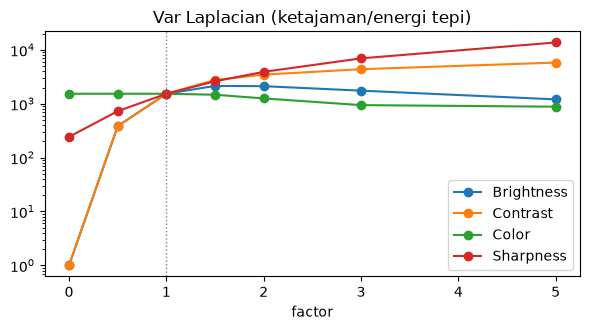

In [28]:
# Var Laplacian dipisah karena skalanya berbeda; sumbu Y log
plt.figure(figsize=(6, 3.4))
for nama, df in dfs.items():
    plt.plot(df.index, df['Var Laplacian'].clip(lower=1), marker='o', label=nama)
plt.yscale('log'); plt.axvline(1, color='gray', ls=':', lw=1)
plt.title('Var Laplacian (ketajaman/energi tepi)'); plt.xlabel('factor'); plt.legend(); plt.tight_layout(); plt.show()

## 8. Catatan atas program dari perkuliahan

Saat mencoba notebook asli, ada beberapa hal yang perlu diperhatikan:
- **Komentar tidak sesuai nilai koefisien.** Misalnya `new_bri = 0.5` tapi komentarnya "*enhanced by a factor of 2.5*"; `new_con = 4` dengan komentar "*factor of 0.3*"; `new_sharp = 3` dengan komentar "*8.3*". Yang berlaku tentu nilai variabelnya, bukan komentarnya.
- Nama variabel `img_brightened` dengan `new_bri = 0.5` sebenarnya menghasilkan gambar **lebih gelap**, bukan lebih terang.
- Nilai yang dipakai (Contrast 4, Color 5) termasuk ekstrem: berdasarkan eksperimen di atas, keduanya sudah menyebabkan sebagian besar piksel ter-clip, sehingga lebih tepat disebut efek artistik daripada *enhancement*.
- Variabel `image` ditimpa dari path (string) menjadi objek gambar — berjalan, tapi lebih rapi jika dipisah (`path` vs `image`).
- Gambar `kopi.bmp` dibaca dari Google Drive pribadi, sehingga notebook tidak bisa dijalankan orang lain tanpa file itu. Notebook ini memakai `skimage.data` agar bisa langsung dijalankan.

## 9. Kesimpulan

1. Keempat operasi `ImageEnhance` memakai satu rumus yang sama, `output = degenerate·(1−f) + asli·f`; koefisien `f` menentukan posisi di antara gambar degenerate (f = 0) dan gambar asli (f = 1), dan f > 1 merupakan ekstrapolasi.
2. **Brightness** mengalikan nilai piksel; paling cepat menimbulkan clipping (f ≥ 1.5) dan, secara tidak langsung, memudarkan warna pada nilai besar.
3. **Contrast** meregangkan nilai di sekitar rata-rata luminans; menaikkan Std L secara linier dan ikut menaikkan saturasi.
4. **Color** hanya mengubah saturasi, nyaris tanpa memengaruhi kecerahan dan kontras — operasi dengan efek paling terisolasi.
5. **Sharpness** memperkuat detail skala piksel (unsharp masking); efeknya halus pada tampilan penuh, tetapi pada f besar memperkuat noise dan menimbulkan halo.
6. Untuk *enhancement* yang tetap natural, koefisien sebaiknya dijaga dekat 1 (kira-kira 0.7–1.5, Sharpness hingga ~2). Nilai jauh di atas itu menyebabkan hilangnya informasi akibat clipping yang tidak bisa dikembalikan.